Part 1: Understanding Product Categories

In [2]:
import pandas as pd

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df=pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
# Frequency table 
frequency_table = df['category'].value_counts()

# Calculating the proportion of each unique value in the 'category'
#normalize =true es el porcentaje 
proportion_table = df['category'].value_counts(normalize=True)

frequency_table, proportion_table

#Which are the top 5 most listed product categories?
# Sports & Outdoors - Beauty - Handmade Clothing, Shoes & Accessories - Bath & Body - Birthday Gifts 


(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Alexa Built-In Devices                       107
 Motorbike Chassis                            107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Alexa Built-In Devices                    0.000044
 Motorbike Chassis       

In [5]:
frequency_table_top_5=frequency_table.head(5)
frequency_table_top_5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/4q/413qpbj17ks9bgdzl52cpx9m0000gn/T/ipykernel_7180/1109303799.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table_top_5.index, y=frequency_table_top_5.values, palette="Set3");


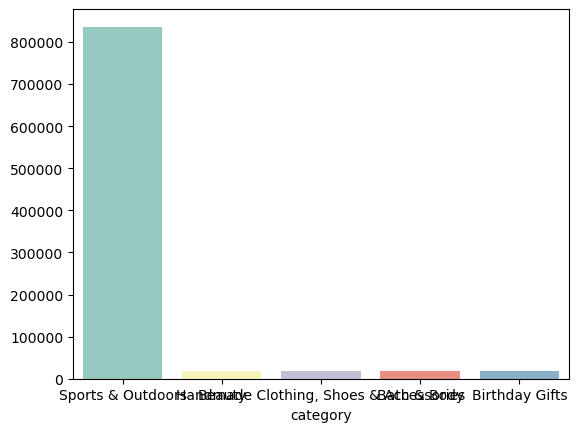

In [6]:
#hacer una gráfica de barras con todas las categorías pero se ve mal. 
#lo hago con las 5 primeras categorías y se sigue viendo mal por los nombres. 
sns.barplot(x=frequency_table_top_5.index, y=frequency_table_top_5.values, palette="Set3");

plt.show()

/var/folders/4q/413qpbj17ks9bgdzl52cpx9m0000gn/T/ipykernel_7180/1895948233.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table_top_5.index, y=frequency_table_top_5.values, palette="Set3")


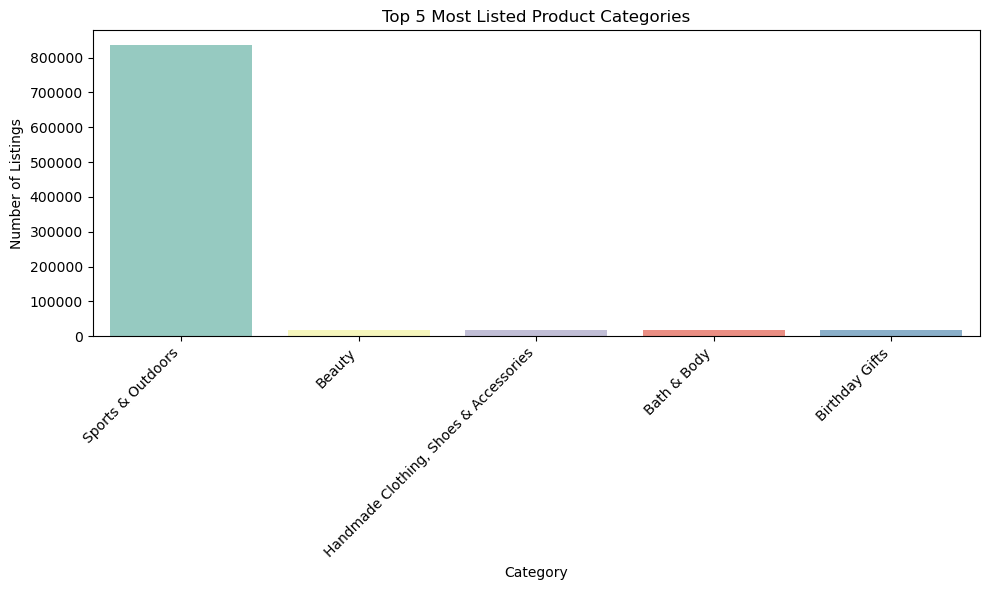

In [7]:
#rotamos las etiquetas para que se vean bien 
plt.figure(figsize=(10, 6)) #esto mejora la escaleta 
sns.barplot(x=frequency_table_top_5.index, y=frequency_table_top_5.values, palette="Set3")
plt.title("Top 5 Most Listed Product Categories")
plt.ylabel("Number of Listings")
plt.xlabel("Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [8]:
#vamos a hacer un pie chart con los top 5 
# Crear un diccionario de nombres abreviados
short_labels = {
    "Clothing, Shoes & Accessories": "Clothing",
    "Sports & Outdoors": "Sports",
    "Beauty": "Beauty",
    "Handmade": "Handmade",
    "Bath & Body": "Bath"
}

# Reindexar la serie con nombres más cortos
frequency_table_top_5_short = frequency_table_top_5.rename(index=short_labels)

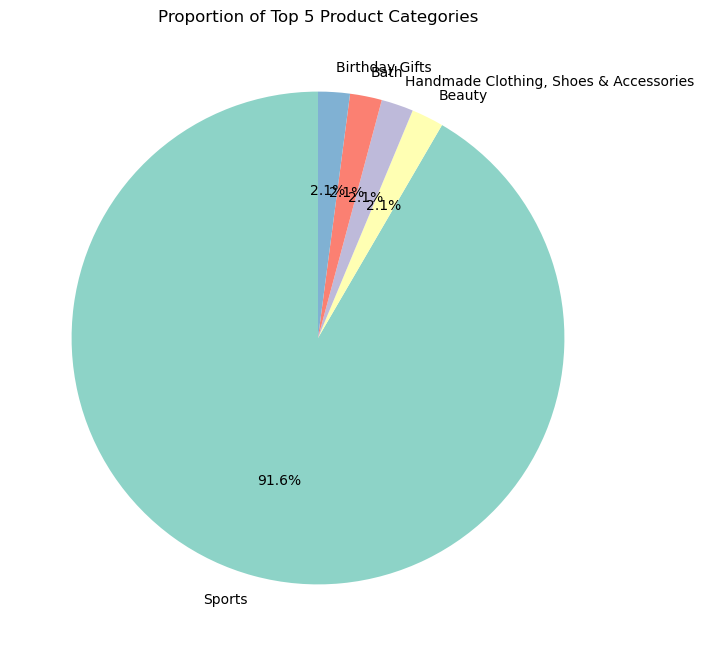

In [9]:
# Pie chart con etiquetas abreviadas
plt.figure(figsize=(8, 8))
frequency_table_top_5_short.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3"),
    labels=frequency_table_top_5_short.index
)
plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("")  # Quita etiqueta del eje Y
plt.show()

Part 2: Delving into Product Pricing


Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [10]:
mean_price = df['price'].mean()
median_price= df['price'].median()
mode_price = df['price'].mode()[0]
iqr= df ['price'].quantile(0.75)-df ['price'].quantile(0.25) #rango intercuartil 
mean_price, median_price , mode_price

(89.24380943923663, 19.09, 9.99)

Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [13]:
mode_price = df['price'].mode()[0]
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])
iqr= df ['price'].quantile(0.75)-df ['price'].quantile(0.25) #rango intercuartil, contiene el 50% de los datos.
print("CONCLUSIÓN: mucha variedad de precios la mayoria son baratos pero hay algunos caros.")
print (f"""Mode:{mode_price},
       Variance: {variance_price}
       Range: {range_price}
       IQR:{iqr}
        """)
variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price

CONCLUSIÓN: mucha variedad de precios la mayoria son baratos pero hay algunos caros.
Mode:9.99,
       Variance: 119445.4853225653
       Range: 100000.0
       IQR:36.0
        


(119445.4853225653,
 345.6088617535223,
 0.0,
 100000.0,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


In [14]:
skewness_price = df['price'].skew()
kurtosis_price = df['price'].kurtosis()

skewness_price, kurtosis_price

#simetría skewness
#concentración de datos es kurtosisi
#kurtosisi alta, como este caso. significa que lo de los extremos se asemeja al centro 

(27.492977566280338, 4241.616412866518)

In [15]:
# resultado de arriba: (27.492977566280338, 4241.616412866518)
# La asimetría (skewness) muy alta y la kurtosis extrema indican que tienes muchos valores pequeños y unos pocos muy grandes (outliers).
#para que esto se vea hay que  limitar el rango para enfocarse en el 99% de los datos
#Limitar los valores a un rango razonable (por ejemplo, hasta el percentil 95). Y hacer histogramas y boxplot con esto. 

In [16]:
# Limpiar precios nulos o negativos (si los hay)
df = df[df['price'].notnull() & (df['price'] >= 0)]
# Calcular percentiles
p95 = df['price'].quantile(0.95)
print(f"95th percentile: {p95}")
# Crear nuevo dataframe sin outliers extremos
df_trimmed = df[df['price'] <= p95]
print(df_trimmed.head())

95th percentile: 349.5
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


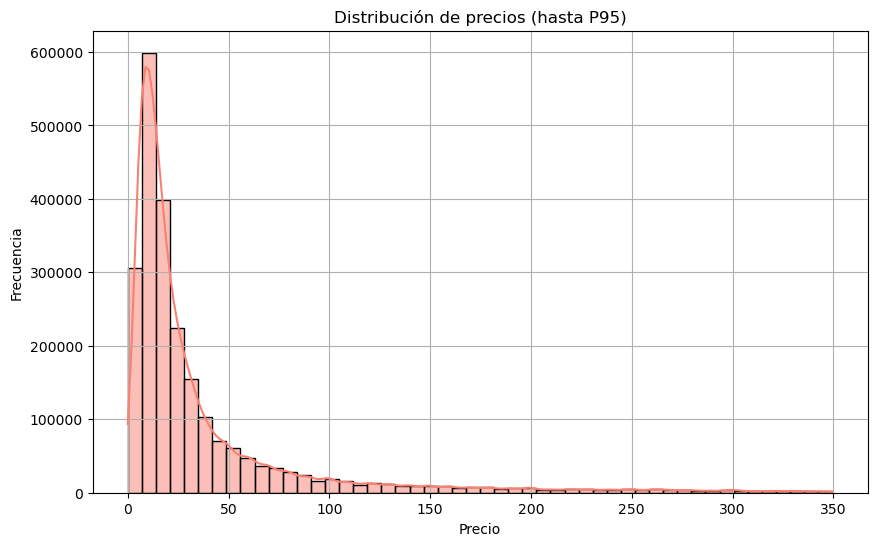

In [ ]:
# Histograma con datos recortados
plt.figure(figsize=(10, 6))
sns.histplot(df_trimmed['price'], bins=50, kde=True, color="salmon")
plt.title("Distribución de precios (hasta P95)")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.grid(True)
plt.show()

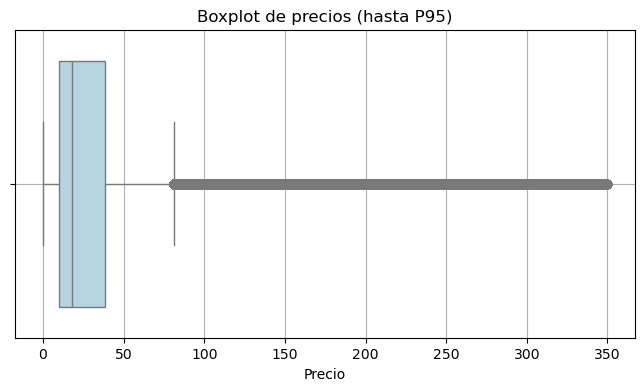

In [ ]:
# Boxplot con datos recortados
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_trimmed['price'], color="lightblue")
plt.title("Boxplot de precios (hasta P95)")
plt.xlabel("Precio")
plt.grid(True)
plt.show()

Part 3: Unpacking Product Ratings

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?


Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?



Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [ ]:
#para quitar la notación científica (que al final de los númerosopnga e+06 elevados)
pd.set_option("display.float_format", "{:.2f}".format)
print(df['stars'].describe())

pd.reset_option("display.float_format") #volver a actiivar la notación científica

count   2443651.00
mean          2.15
std           2.19
min           0.00
25%           0.00
50%           0.00
75%           4.40
max           5.00
Name: stars, dtype: float64


In [23]:
mode = df['stars'].mode()[0]
variance = df['stars'].var()
min_price = df['stars'].min()
max_price = df['stars'].max()
range_price = max_price - min_price
iqr= df ['stars'].quantile(0.75)-df ['stars'].quantile(0.25) #rango intercuartil, contiene el 50% de los datos.
print (f"""Mode:{mode},
       Variance: {variance}
       Range: {range_price}
       IQR:{iqr}
        """)
print(
"""- La media es baja
- La mediana y la moda es 0 porque muchos productos no tienen clasificación 
- La varianza es 4 y pico, mucha dispersión enlas calificaciones
- El rango es 5, por lo que las calificaciones abarcan ese rango 
- El IQR indica que la mayoría de calificaciones se agrupan entre el 0 y 4,4.""" )


Mode:0.0,
       Variance: 4.81743402976196
       Range: 5.0
       IQR:4.4
        
- La media es baja
- La mediana y la moda es 0 porque muchos productos no tienen clasificación 
- La varianza es 4 y pico, mucha dispersión enlas calificaciones
- El rango es 5, por lo que las calificaciones abarcan ese rango 
- El IQR indica que la mayoría de calificaciones se agrupan entre el 0 y 4,4.


In [30]:
#3 shape of the distribution

skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

Las calificaciones no siguen una distribución normal. Sin emabrgo, están equilibradas sin mucha inclinación.

In [ ]:
#visualizacion
df['stars'].value_counts()

stars
0.00    1225641
4.50     151577
4.60     136995
4.40     136165
5.00     128492
4.30     112564
4.70      94566
4.20      86871
4.00      66089
4.10      65115
4.80      41858
3.90      36555
3.80      27876
3.70      21137
3.60      16219
3.50      14673
3.00      12819
4.90      11081
3.40      10355
1.00       8484
3.30       8269
3.20       5771
3.10       4679
2.00       3901
2.90       3341
2.80       2306
2.70       2104
2.50       2103
2.60       1579
2.40       1060
2.30        734
2.20        602
2.10        540
1.50        404
1.90        300
1.80        249
1.70        177
1.40        149
1.60        147
1.30         78
1.20         23
1.10          3
Name: count, dtype: int64

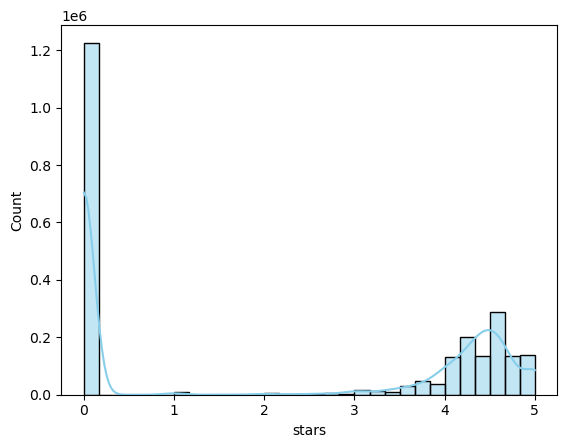

In [29]:
sns.histplot(df['stars'],kde=True,bins=30, color="skyblue")
plt.show()

In [26]:
percentage_zeros=(df['stars'].value_counts().get(0,0)/len(df))*100
percentage_zeros

50.15613931776674

- La mitad no tienen calificación y el resto se concentran mucho entre 3 y 5 